<a href="https://colab.research.google.com/github/hyunwook3910/hackathon/blob/main/trash_classfication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mostafaabla/garbage-classification")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'garbage-classification' dataset.
Path to dataset files: /kaggle/input/garbage-classification


In [2]:
# 1. 데이터 학습 전 데이터 확인
import os, random
from collections import Counter
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# 1) 폴더 구조 보기 (깊이 3까지)
for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 3:
        print("  " * depth + os.path.basename(root), f"(폴더 {len(dirs)}, 파일 {len(files)})")

garbage-classification (폴더 1, 파일 0)
  garbage_classification (폴더 12, 파일 0)
    metal (폴더 0, 파일 769)
    white-glass (폴더 0, 파일 775)
    biological (폴더 0, 파일 985)
    paper (폴더 0, 파일 1050)
    brown-glass (폴더 0, 파일 607)
    battery (폴더 0, 파일 945)
    trash (폴더 0, 파일 697)
    cardboard (폴더 0, 파일 891)
    shoes (폴더 0, 파일 1977)
    clothes (폴더 0, 파일 5325)
    plastic (폴더 0, 파일 865)
    green-glass (폴더 0, 파일 629)


In [4]:
# 2) 클래스 폴더가 있는 위치 자동 탐색: 이미지 파일을 직접 가진 폴더들의 부모
IMG_EXT = (".jpg", ".jpeg", ".png")
class_dirs = {}
for root, dirs, files in os.walk(path):
    imgs = [f for f in files if f.lower().endswith(IMG_EXT)]
    if imgs:
        class_dirs[root] = imgs

data_dir = os.path.dirname(next(iter(class_dirs)))
print("data_dir:", data_dir)

# 3) 클래스별 개수 (불균형 확인)
rows = [(os.path.basename(d), len(f)) for d, f in class_dirs.items()]
df = pd.DataFrame(rows, columns=["class", "count"]).sort_values("count", ascending=False)
df["ratio(%)"] = (df["count"] / df["count"].sum() * 100).round(1)
print(df.to_string(index=False))
print("전체:", df["count"].sum(), "| 클래스 수:", len(df))

#데이터 불균형이 큼. clothes가 34.3%라 clothes라고 구분할 확률이 높다.

data_dir: /kaggle/input/garbage-classification/garbage_classification
      class  count  ratio(%)
    clothes   5325      34.3
      shoes   1977      12.7
      paper   1050       6.8
 biological    985       6.3
    battery    945       6.1
  cardboard    891       5.7
    plastic    865       5.6
white-glass    775       5.0
      metal    769       5.0
      trash    697       4.5
green-glass    629       4.1
brown-glass    607       3.9
전체: 15515 | 클래스 수: 12


In [5]:
# 4) 이미지 크기·모드 확인 (클래스마다 30장씩 표본)
random.seed(42)
sizes, modes = [], Counter()
for d, files in class_dirs.items():
    for f in random.sample(files, min(30, len(files))):
        with Image.open(os.path.join(d, f)) as im:
            sizes.append(im.size)
            modes[im.mode] += 1

sz = pd.DataFrame(sizes, columns=["width", "height"])
print(sz.describe().round(1))
print("모드:", dict(modes))   # RGB가 아닌 것(RGBA, L 등)이 섞여 있는지 확인

#사진의 크기가 제각각이다.
#RGB 파일이 아닌 P가 있음.

       width  height
count  360.0   360.0
mean   317.0   283.1
std    124.3   111.3
min    132.0   115.0
25%    225.0   200.0
50%    259.0   225.0
75%    400.0   384.0
max    865.0   711.0
모드: {'RGB': 359, 'P': 1}


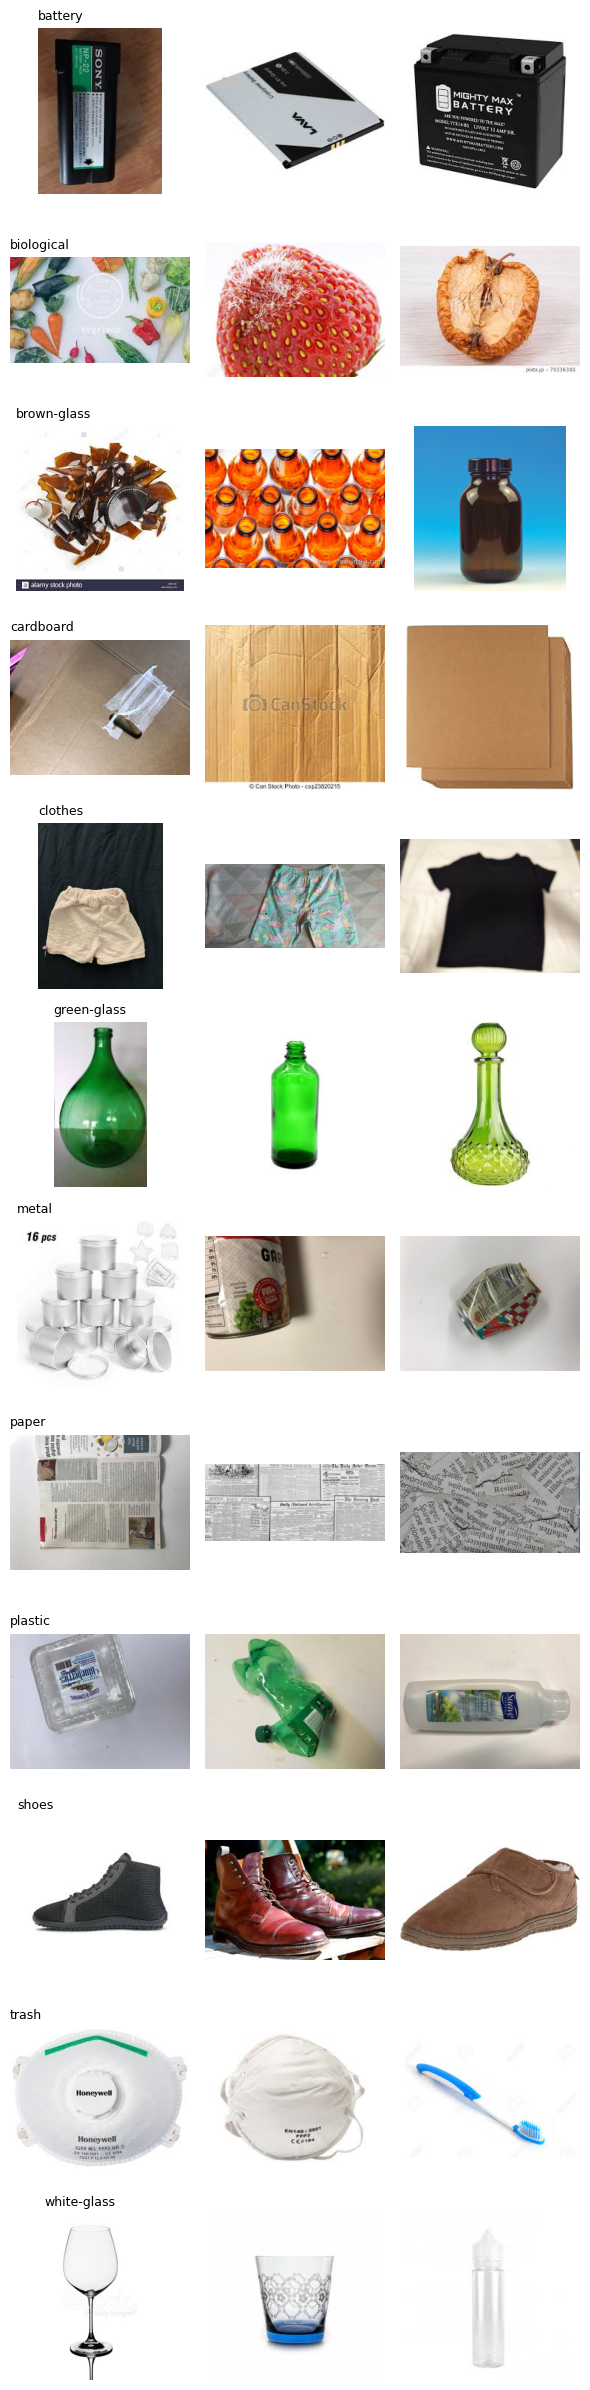

In [6]:
# 5) 클래스별 샘플 이미지 (클래스당 3장)
names = sorted(class_dirs, key=lambda d: os.path.basename(d))
fig, axes = plt.subplots(len(names), 3, figsize=(6, 2 * len(names)))
for i, d in enumerate(names):
    for j, f in enumerate(random.sample(class_dirs[d], 3)):
        axes[i, j].imshow(Image.open(os.path.join(d, f)).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(os.path.basename(d), fontsize=9, loc="left")
plt.tight_layout()
plt.show()

In [15]:
import os, random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

data_dir = "/kaggle/input/garbage-classification/garbage_classification"
classes = sorted(os.listdir(data_dir))
class_to_idx = {c: i for i, c in enumerate(classes)}

paths, labels = [], []
for c in classes:
    for f in sorted(os.listdir(os.path.join(data_dir, c))):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            paths.append(os.path.join(data_dir, c, f))
            labels.append(class_to_idx[c])
labels = np.array(labels)
print(len(paths), classes)

# 클래스별로 섞은 뒤 같은 비율로 자른다 (3주차: 섞고 나누기)
rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []
for k in range(len(classes)):
    idx = np.where(labels == k)[0]
    rng.shuffle(idx)
    n_tr, n_va = int(len(idx) * 0.70), int(len(idx) * 0.15)
    train_idx += idx[:n_tr].tolist()
    val_idx   += idx[n_tr:n_tr + n_va].tolist()
    test_idx  += idx[n_tr + n_va:].tolist()

print("train/val/test:", len(train_idx), len(val_idx), len(test_idx))

15515 ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
train/val/test: 10854 2321 2340


In [20]:
IMG = 128

def load_img(p):
    with Image.open(p) as im:
        im = im.convert("RGB").resize((IMG, IMG), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8)          # (128, 128, 3)

X = np.stack([load_img(p) for p in paths])             # (N, 128, 128, 3)
X = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()  # (N, 3, 128, 128): PyTorch는 채널이 앞
y = torch.from_numpy(labels).long()                    # CrossEntropyLoss는 정수 클래스 번호(Long)

print(X.shape, X.dtype, y.shape, y.dtype)

# 다시 쓰려고 저장 (Kaggle이면 /kaggle/working, Colab이면 /content)
torch.save({"X": X, "y": y, "classes": classes,
            "train_idx": train_idx, "val_idx": val_idx, "test_idx": test_idx},
           "garbage_128.pt")

torch.Size([15515, 3, 128, 128]) torch.uint8 torch.Size([15515]) torch.int64


In [16]:
def channel_stats(X, idx, chunk=512):
    s = torch.zeros(3); s2 = torch.zeros(3); n = 0
    for i in range(0, len(idx), chunk):
        b = X[idx[i:i + chunk]].float() / 255.0         # (b, 3, H, W)
        s  += b.sum(dim=(0, 2, 3))
        s2 += (b ** 2).sum(dim=(0, 2, 3))
        n  += b.shape[0] * b.shape[2] * b.shape[3]
    mean = s / n
    std = (s2 / n - mean ** 2).sqrt()
    return mean, std

mean, std = channel_stats(X, train_idx)
print("mean:", mean, "std:", std)

mean: tensor([0.6581, 0.6157, 0.5851]) std: tensor([0.2765, 0.2878, 0.3016])


In [17]:
class GarbageDataset(Dataset):
    def __init__(self, X, y, indices, mean, std):
        self.X, self.y = X, y
        self.indices = indices
        self.mean = mean.view(3, 1, 1)
        self.std = std.view(3, 1, 1)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        x = self.X[j].float() / 255.0                   # 0~1
        x = (x - self.mean) / self.std                  # 학습 기준 표준화
        return x, self.y[j]

train_set = GarbageDataset(X, y, train_idx, mean, std)
val_set   = GarbageDataset(X, y, val_idx,   mean, std)
test_set  = GarbageDataset(X, y, test_idx,  mean, std)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=64, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=64, shuffle=False)
print(len(train_loader), len(val_loader), len(test_loader))   # batch 개수

170 37 37


In [18]:
bx, by = next(iter(train_loader))
print("batch shape:", tuple(bx.shape), bx.dtype)      # (64, 3, 128, 128) float32
print("label:", by.shape, by.dtype)                   # (64,) int64
print("min/max:", bx.min().item(), bx.max().item())
print("nan:", torch.isnan(bx).sum().item())           # 0이어야 함

# 분할마다 클래스 비율이 비슷한지
import pandas as pd
rows = {name: np.bincount(labels[idx], minlength=len(classes))
        for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]}
print(pd.DataFrame(rows, index=classes))

batch shape: (64, 3, 128, 128) torch.float32
label: torch.Size([64]) torch.int64
min/max: -2.3804163932800293 1.3753865957260132
nan: 0
             train  val  test
battery        661  141   143
biological     689  147   149
brown-glass    424   91    92
cardboard      623  133   135
clothes       3727  798   800
green-glass    440   94    95
metal          538  115   116
paper          735  157   158
plastic        605  129   131
shoes         1383  296   298
trash          487  104   106
white-glass    542  116   117


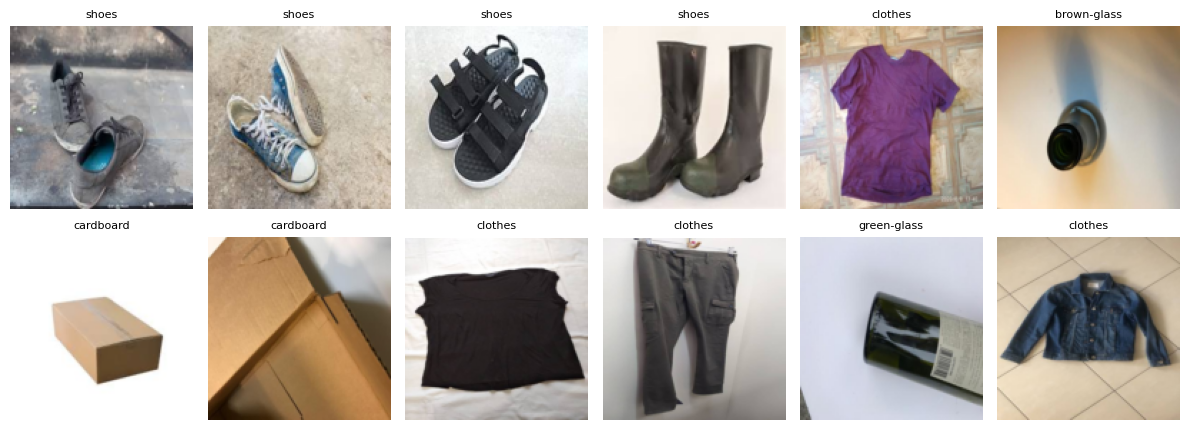

In [19]:
# 표준화를 되돌려 눈으로 확인 (정상적으로 읽혔는지)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, img, lab in zip(axes.flat, bx[:12], by[:12]):
    ax.imshow((img * std.view(3,1,1) + mean.view(3,1,1)).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(classes[lab], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

In [21]:
import time, copy
import torch, torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

N_CLASSES = len(classes)   # 12

class BaseCNN(nn.Module):
    def __init__(self, n_classes=12, in_size=128):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),   nn.ReLU(), nn.MaxPool2d(2),   # 128 → 64
            nn.Conv2d(16, 32, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),   # 64 → 32
            nn.Conv2d(32, 64, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),   # 32 → 16
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16 → 8
        )
        with torch.no_grad():                       # 8주차: 더미 입력으로 Flatten 크기 알아내기
            flat = self.features(torch.zeros(1, 3, in_size, in_size)).numel()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat, 128), nn.ReLU(),
            nn.Linear(128, n_classes),              # softmax는 넣지 않는다 (CrossEntropyLoss가 처리)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = BaseCNN(N_CLASSES).to(device)

# 단계별 shape 추적: 학습 전에 반드시 확인
x = torch.zeros(1, 3, 128, 128, device=device)
with torch.no_grad():
    for layer in list(model.features) + list(model.classifier):
        x = layer(x)
        print(f"{layer.__class__.__name__:10s} {tuple(x.shape)}")

n_params = sum(p.numel() for p in model.parameters())
print("파라미터 수:", n_params)   # 1,147,692가 나와야 정상

device: cuda
Conv2d     (1, 16, 128, 128)
ReLU       (1, 16, 128, 128)
MaxPool2d  (1, 16, 64, 64)
Conv2d     (1, 32, 64, 64)
ReLU       (1, 32, 64, 64)
MaxPool2d  (1, 32, 32, 32)
Conv2d     (1, 64, 32, 32)
ReLU       (1, 64, 32, 32)
MaxPool2d  (1, 64, 16, 16)
Conv2d     (1, 128, 16, 16)
ReLU       (1, 128, 16, 16)
MaxPool2d  (1, 128, 8, 8)
Flatten    (1, 8192)
Linear     (1, 128)
ReLU       (1, 128)
Linear     (1, 12)
파라미터 수: 1147692


In [22]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 15

def run_epoch(loader, train):
    model.train(train)                               # train / eval 전환
    total_loss, correct, n = 0.0, 0, 0
    cm = torch.zeros(N_CLASSES * N_CLASSES, dtype=torch.long)
    with torch.enable_grad() if train else torch.no_grad():
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            out = model(bx)                          # 1) 예측
            loss = loss_fn(out, by)                  # 2) 손실
            if train:
                optimizer.zero_grad()                # 3) 기울기 초기화
                loss.backward()                      # 4) 역전파
                optimizer.step()                     # 5) 파라미터 수정
            pred = out.argmax(dim=1)
            total_loss += loss.item() * len(by)
            correct += (pred == by).sum().item()
            n += len(by)
            cm += torch.bincount((by * N_CLASSES + pred).cpu(), minlength=N_CLASSES ** 2)
    cm = cm.view(N_CLASSES, N_CLASSES).float()
    bal_acc = (cm.diag() / cm.sum(dim=1)).mean().item()   # 클래스별 recall의 평균
    return total_loss / n, correct / n, bal_acc

hist = {k: [] for k in ["tr_loss", "tr_acc", "va_loss", "va_acc", "va_bal"]}
best_val, best_state = float("inf"), None
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc, _        = run_epoch(train_loader, train=True)
    va_loss, va_acc, va_bal   = run_epoch(val_loader,   train=False)
    for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc, va_bal]):
        hist[k].append(v)
    if va_loss < best_val:                           # 검증 손실이 가장 낮은 시점을 저장
        best_val, best_epoch = va_loss, ep
        best_state = copy.deepcopy(model.state_dict())
    print(f"ep {ep:2d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.3f} bal {va_bal:.3f} | {time.time()-t0:.0f}s")

torch.save(best_state, "base_cnn_best.pt")
print("best epoch:", best_epoch, "| val loss:", round(best_val, 4))

ep  1 | train loss 1.4971 acc 0.516 | val loss 1.1074 acc 0.639 bal 0.526 | 6s
ep  2 | train loss 0.9451 acc 0.691 | val loss 0.8799 acc 0.713 bal 0.625 | 11s
ep  3 | train loss 0.7435 acc 0.754 | val loss 0.8072 acc 0.740 bal 0.658 | 16s
ep  4 | train loss 0.6050 acc 0.800 | val loss 0.8116 acc 0.744 bal 0.658 | 21s
ep  5 | train loss 0.4903 acc 0.837 | val loss 0.8233 acc 0.758 bal 0.672 | 26s
ep  6 | train loss 0.3847 acc 0.867 | val loss 0.8177 acc 0.760 bal 0.680 | 31s
ep  7 | train loss 0.2906 acc 0.902 | val loss 0.8805 acc 0.764 bal 0.676 | 36s
ep  8 | train loss 0.2094 acc 0.930 | val loss 0.9616 acc 0.769 bal 0.684 | 41s
ep  9 | train loss 0.1553 acc 0.948 | val loss 0.9807 acc 0.768 bal 0.692 | 46s
ep 10 | train loss 0.1212 acc 0.961 | val loss 1.0839 acc 0.766 bal 0.687 | 51s
ep 11 | train loss 0.1149 acc 0.963 | val loss 1.1517 acc 0.756 bal 0.701 | 57s
ep 12 | train loss 0.0664 acc 0.979 | val loss 1.5047 acc 0.763 bal 0.678 | 62s
ep 13 | train loss 0.0830 acc 0.971 | val

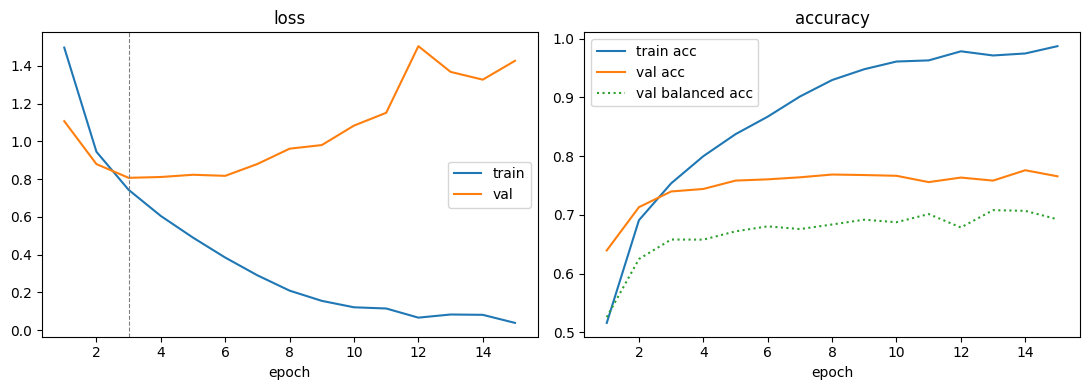

학습-검증 정확도 차이(마지막): 0.222


In [23]:
ep_axis = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep_axis, hist["tr_loss"], label="train"); ax[0].plot(ep_axis, hist["va_loss"], label="val")
ax[0].axvline(best_epoch, color="gray", ls="--", lw=0.8); ax[0].set_title("loss"); ax[0].legend()
ax[1].plot(ep_axis, hist["tr_acc"], label="train acc"); ax[1].plot(ep_axis, hist["va_acc"], label="val acc")
ax[1].plot(ep_axis, hist["va_bal"], label="val balanced acc", ls=":")
ax[1].set_title("accuracy"); ax[1].legend()
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()
print("학습-검증 정확도 차이(마지막):", round(hist["tr_acc"][-1] - hist["va_acc"][-1], 3))